# Malicious URL classification - Task 3 rerun

Zhanna Azatkyzy, Dariyana Gabdylshukir

This notebook inspects the completed domain-disjoint RPS experiment. It does not rerun timing. Labels are malicious/benign, not phishing-specific. Saved outputs come from the recorded Windows run; this notebook displays and validates those records.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
root = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
run = root / 'data/review_runs/20261105T122952Z_dbea27e6'
meta = json.loads((run / 'metadata.json').read_text())
assert meta['status'] == 'complete'
print('Run:', meta['run_id'])
print('Recorded environment:', meta['python'], meta['platform'])
print(meta['audit'])

Run: 20261105T122952Z_dbea27e6
Recorded environment: 3.11.9 Windows-10-10.0.22631-SP0
{'source_rows': 20000, 'retained_rows': 19979, 'excluded_rows': 21, 'invalid_domain_rows': 21, 'conflicting_urls': 0, 'unique_domains': 10858, 'class_counts': {'0': 16768, '1': 3211}, 'positive_class': 'malicious; no phishing-specific label'}


## 1. Validate saved domain splits

Thirty percent of groups are held out; URL proportions vary. Repeats share observations.

In [2]:
df = pd.read_csv(run / 'cleaned_dataset.csv')
rows = []
for p in sorted(run.glob('split_*.npz')):
    s = np.load(p)
    tr, te = s['train'], s['test']
    assert not set(tr) & set(te)
    assert len(set(tr) | set(te)) == len(df)
    overlap = len(set(df.iloc[tr].domain) & set(df.iloc[te].domain))
    assert overlap == 0
    rows.append({'split': p.stem, 'train': len(tr), 'test': len(te), 'shared_domains': overlap})
assert len(rows) == 10
display(pd.DataFrame(rows))

,split,train,test,shared_domains
0,split_01,13845,6134,0
1,split_02,14281,5698,0
2,split_03,13252,6727,0
3,split_04,13429,6550,0
4,split_05,14531,5448,0
5,split_06,14281,5698,0
6,split_07,13189,6790,0
7,split_08,13298,6681,0
8,split_09,13487,6492,0
9,split_10,14095,5884,0


## 2. Classification quality

Mean and sample SD over ten repeats; 95% bootstrap intervals use 2,000 resamples, seed 42. Intervals are descriptive and conditional on the dataset.

In [3]:
q = pd.read_csv(root / 'data/processed/quality_summary.csv')
display(q[['model','feature_set','f1_mean','f1_sd','f1_ci_low','f1_ci_high','recall_mean']].round(4))

,model,feature_set,f1_mean,f1_sd,f1_ci_low,f1_ci_high,recall_mean
0,logistic_regression,full,0.3238,0.0276,0.3080,0.3397,0.2002
1,logistic_regression,selected,0.2135,0.0195,0.2016,0.2251,0.1217
2,random_forest,full,0.5902,0.0199,0.5778,0.6015,0.5545
3,random_forest,selected,0.3673,0.0150,0.3589,0.3767,0.2962
4,svm,full,0.3933,0.0287,0.3755,0.4101,0.2551
5,svm,selected,0.2762,0.0235,0.2637,0.2917,0.1652
6,xgboost,full,0.6023,0.0178,0.5919,0.6129,0.5117
7,xgboost,selected,0.3699,0.0184,0.3598,0.3814,0.2539


## 3. Latency and guardrails

Each request contains one URL. Latency includes scheduler lag, queueing and feature extraction plus prediction. Quantiles are calculated per repeat then averaged. Warm-up is excluded. Guardrails use the worst repeat p99, mean recall and zero recorded execution errors.

In [4]:
g = pd.read_csv(root / 'data/processed/guardrails.csv')
display(g[['model','feature_set','target_rps','p50_ms','p95_ms','p99_ms','worst_repeat_p99_ms','total_errors','recall_ok','latency_ok','passed']].round(3))

,model,feature_set,target_rps,p50_ms,p95_ms,p99_ms,worst_repeat_p99_ms,total_errors,recall_ok,latency_ok,passed
0,logistic_regression,full,50.0,1.918,3.831,18.640,20.191,0,False,True,False
1,logistic_regression,full,200.0,1.458,2.594,16.468,22.689,0,False,True,False
2,logistic_regression,full,500.0,0.901,2.520,15.813,26.446,0,False,True,False
3,logistic_regression,selected,50.0,1.891,3.406,17.408,19.057,0,False,True,False
4,logistic_regression,selected,200.0,1.455,2.749,17.563,22.790,0,False,True,False
5,logistic_regression,selected,500.0,0.912,2.613,16.527,25.596,0,False,True,False
6,random_forest,full,50.0,6.017,9.022,21.259,25.279,0,False,True,False
7,random_forest,full,200.0,4.354,5.068,12.996,22.408,0,False,True,False
8,random_forest,full,500.0,1066.169,2150.111,2265.842,2306.906,0,False,False,False
9,random_forest,selected,50.0,5.934,8.922,19.430,23.121,0,False,True,False


## 4. Figures

Figure 1 shows mean repeat-level latency quantiles and bootstrap intervals. Figure 2 shows F1 over repeats and latency at 50 requests/s.

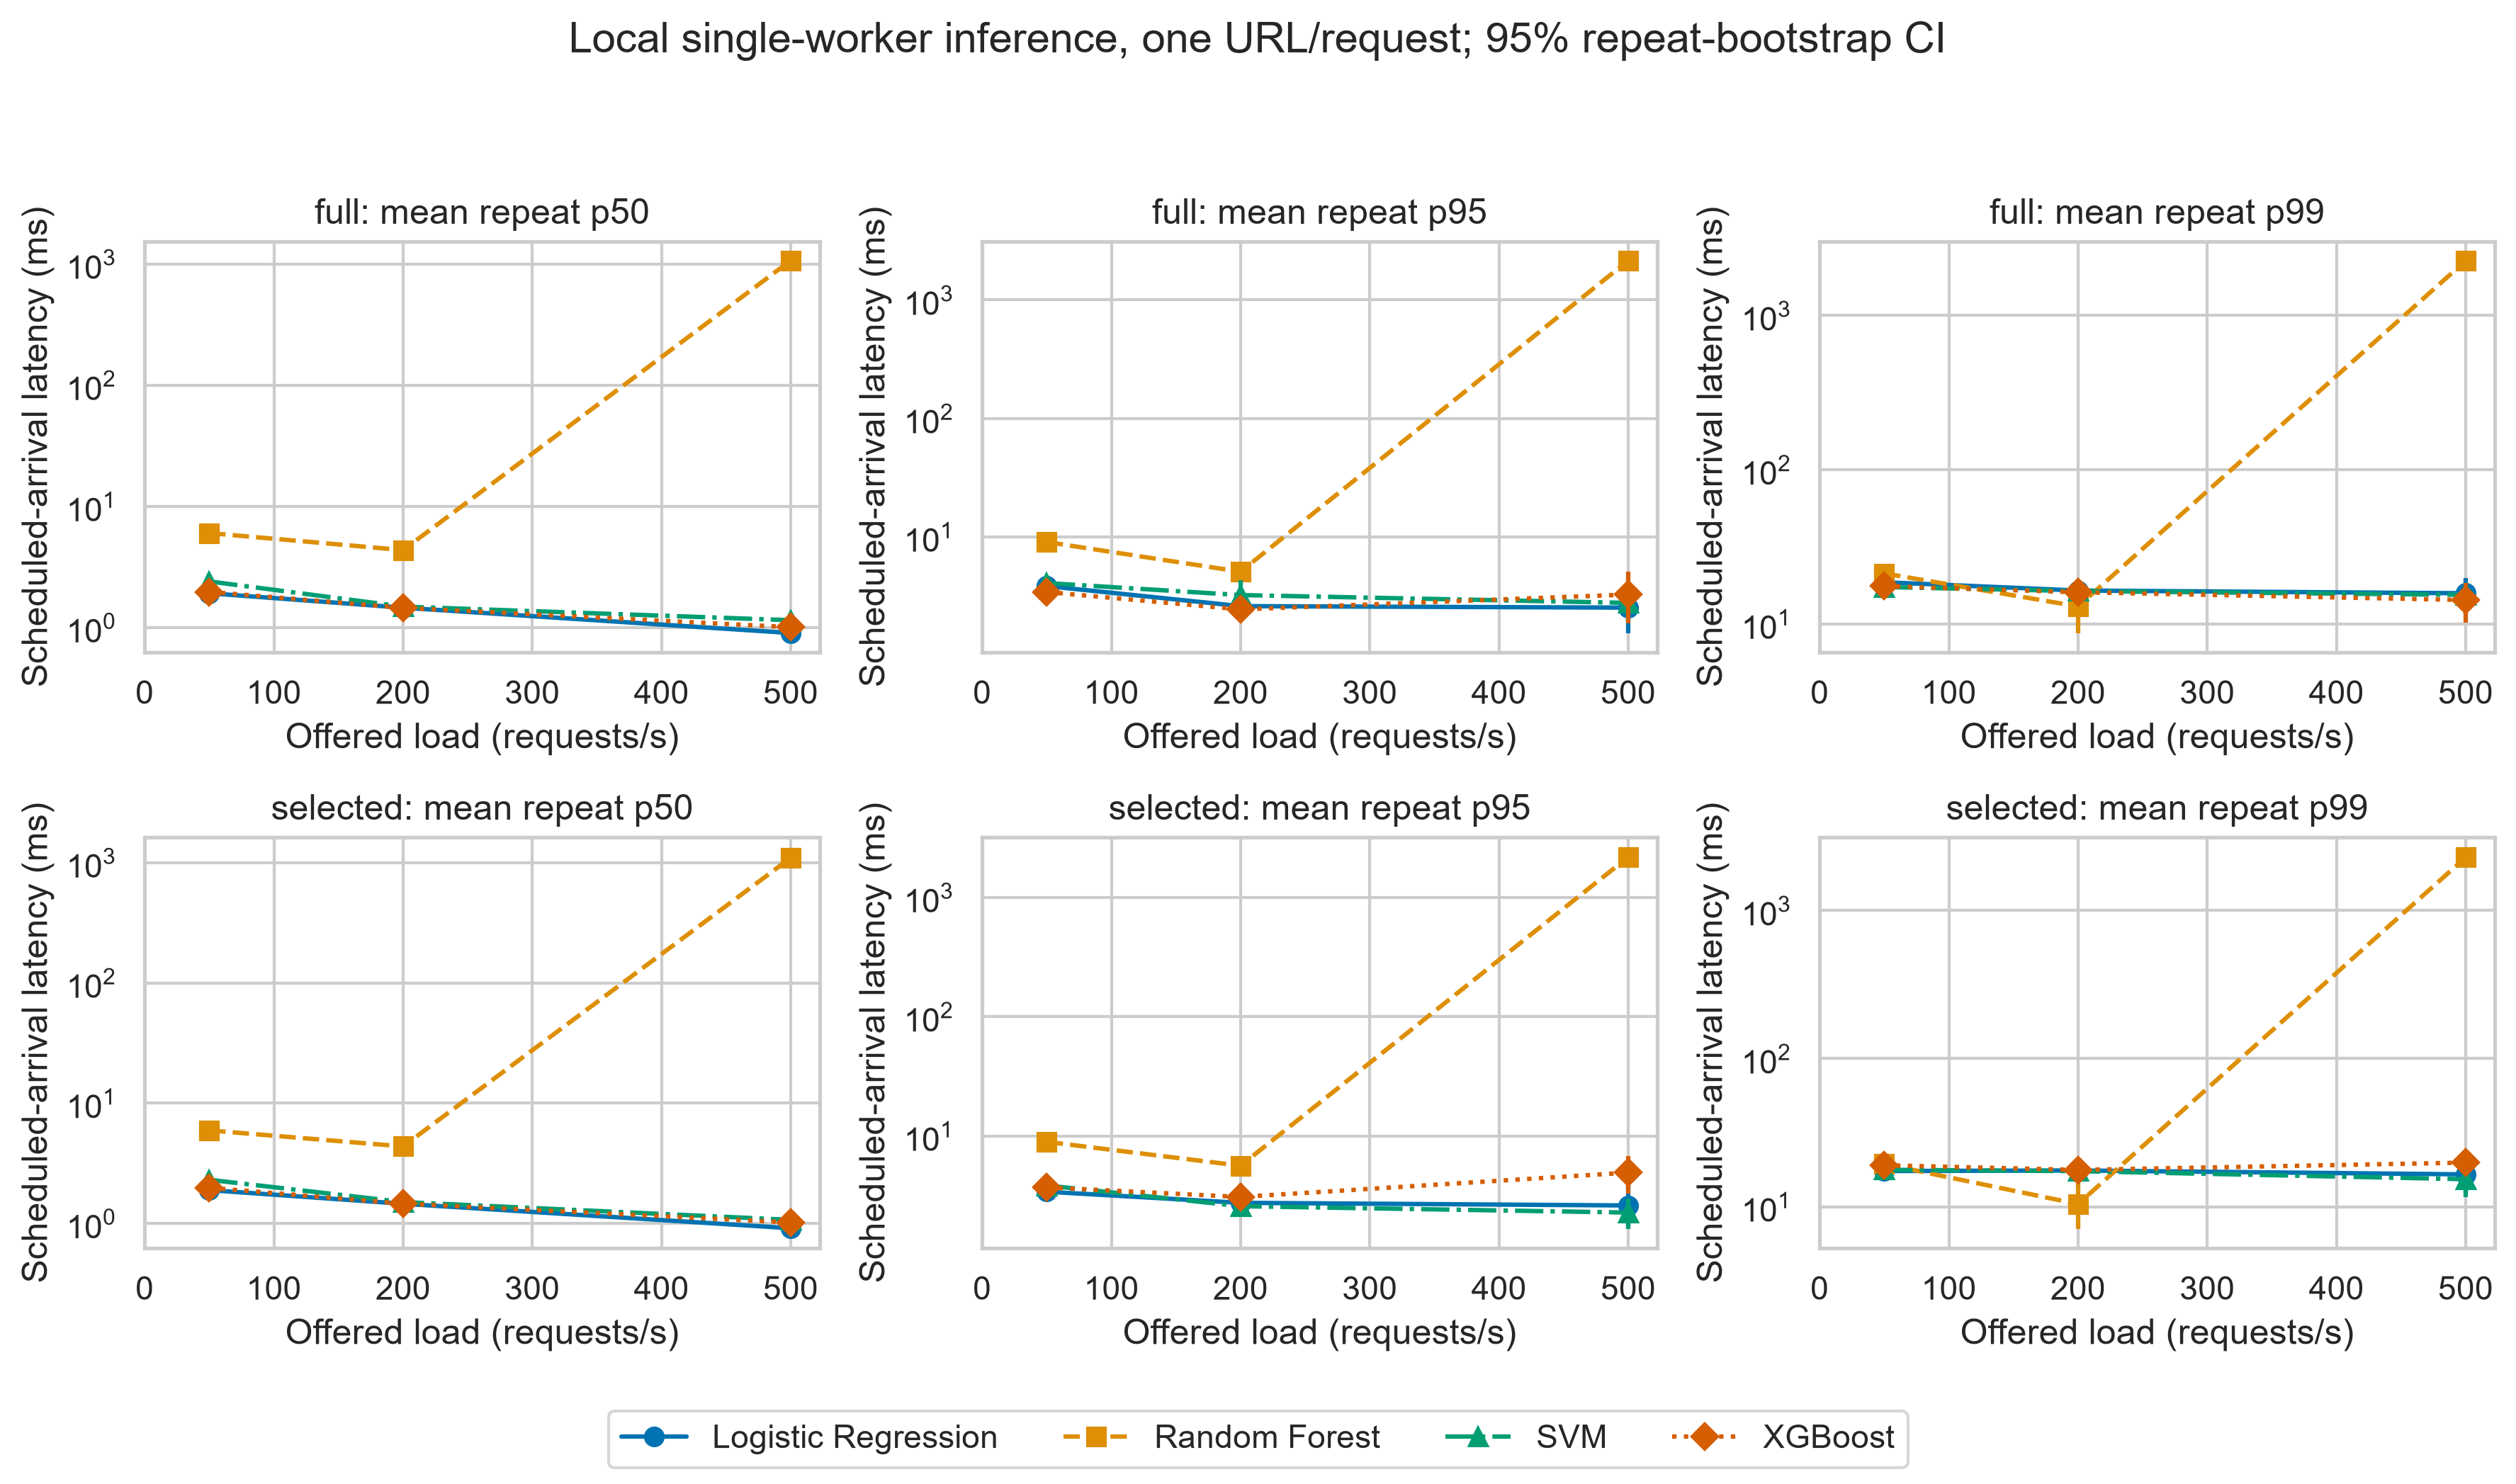

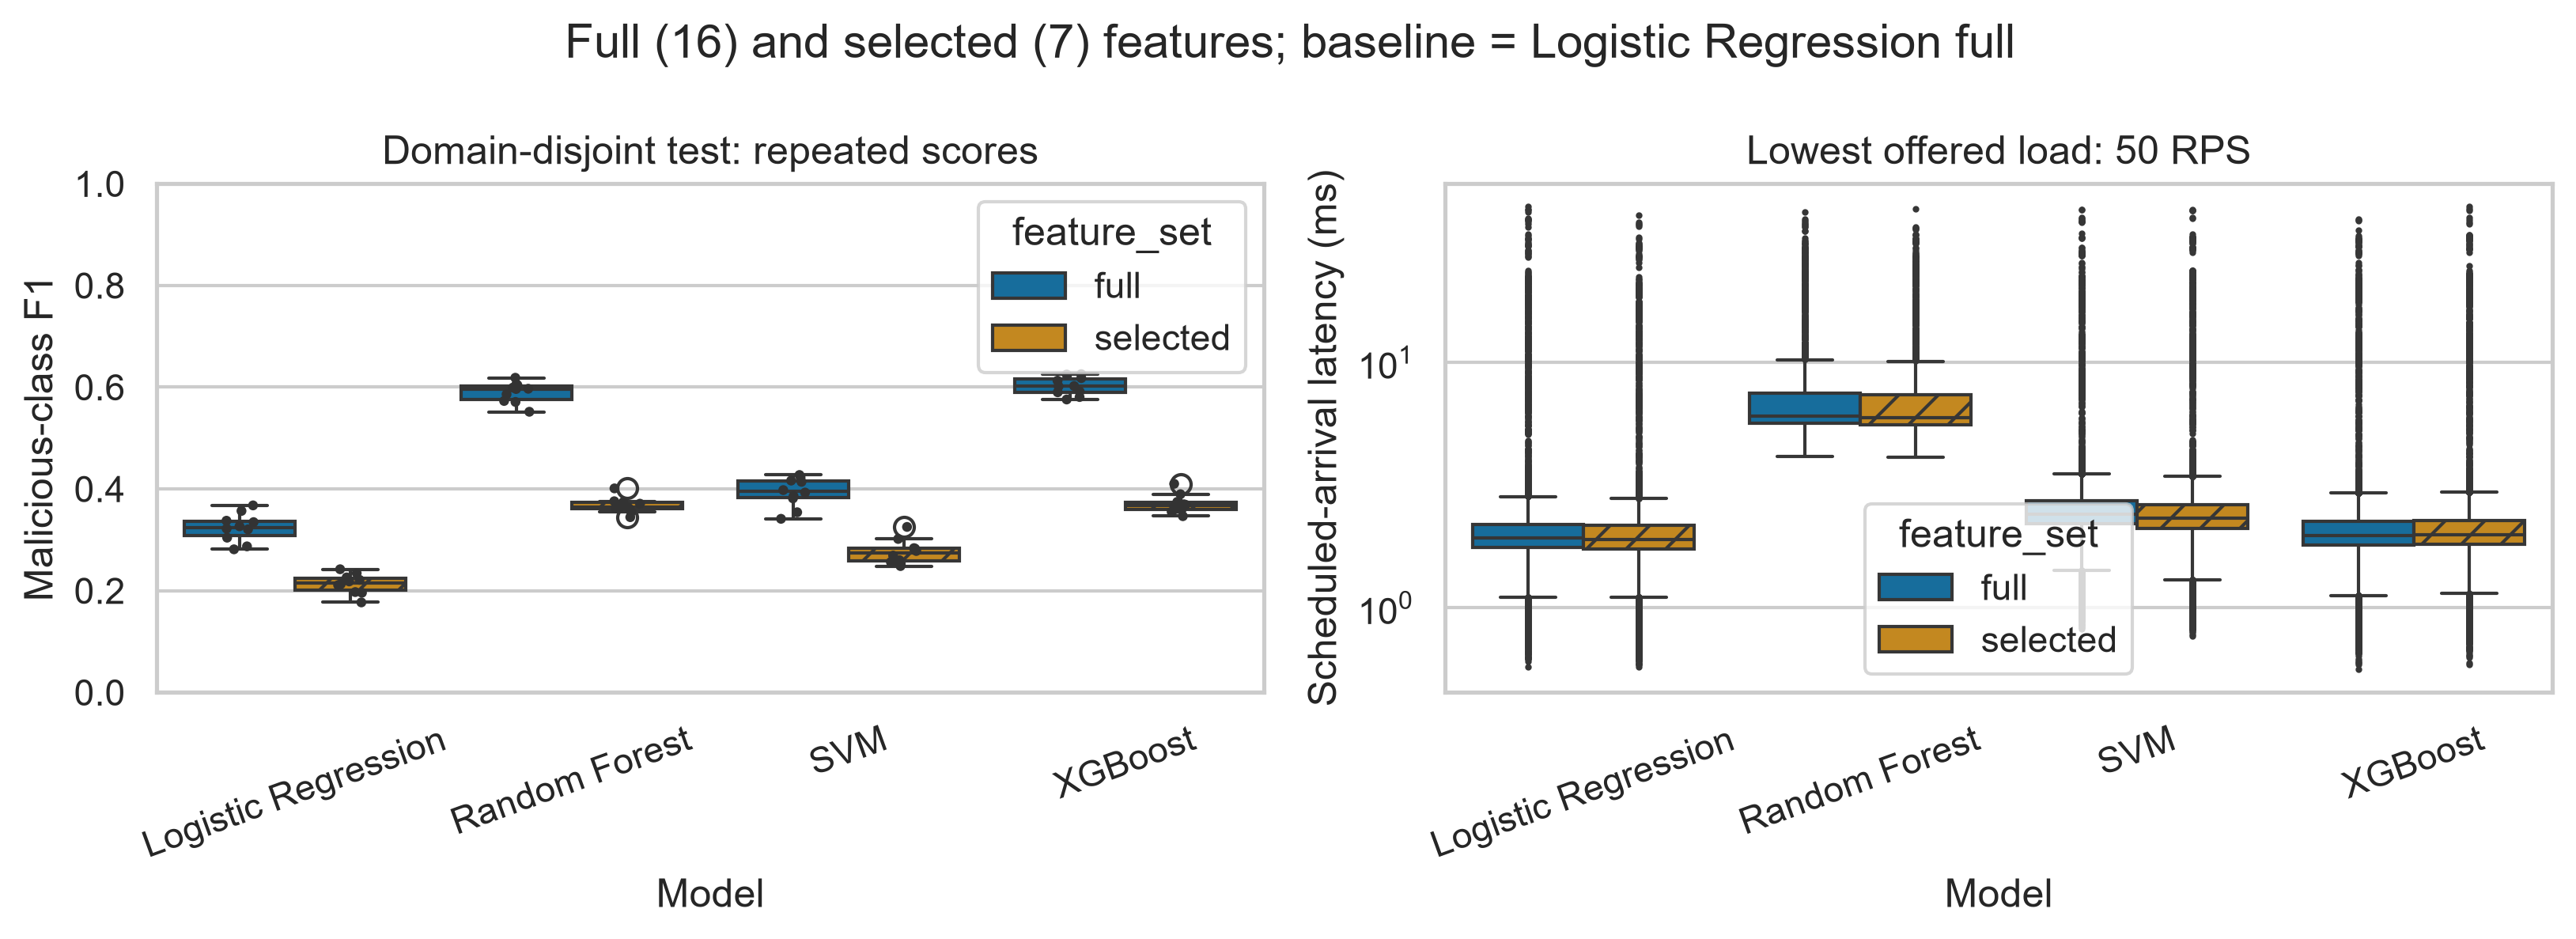

In [5]:
display(Image(filename=str(root / 'reports/figures/fig1_latency_vs_rps.png')))
display(Image(filename=str(root / 'reports/figures/fig2_distributions.png')))

## 5. Conclusions and limitations

XGBoost with 16 features has the highest observed mean F1 (0.602), followed by Random Forest (0.590), SVM (0.393), and the Logistic Regression baseline (0.324). Seven features lower mean F1 for every model. These comparisons are descriptive; no statistical rejection of a null hypothesis is claimed.

Random Forest has the highest mean recall (0.555), below the predefined 0.80 threshold. No configuration passes all guardrails. All 240,000 evaluation requests complete without recorded operational errors. Random Forest fails the latency guardrail at 500 requests/s: mean repeat-level p99 is about 2.27-2.28 seconds and worst repeat-level p99 is 2.31-2.42 seconds. Queue measurements show backlog in these finite trials. All configurations pass the latency threshold at 50 and 200 requests/s; the other three models also pass at 500 requests/s.

XGBoost with all features offers a useful observed F1-latency trade-off, but does not meet the recall requirement. The experiment compares fixed model settings; it does not tune decision thresholds or class weights. Any future tuning must use training/validation data and a fresh held-out evaluation, rather than optimizing these test results.

The labels distinguish malicious and benign URLs, without a separate phishing category. Domain-disjoint splitting removes domain overlap within each split, but does not guarantee independence of campaigns, URL templates or repeated splits. Timing depends on the recorded Windows environment, operating-system scheduling and local worker design. Lower median latency at a higher arrival rate is observed for some models and should not be interpreted as a general causal speedup.

The full lexical extractor is evaluated even for selected features. To recompute tables and figures from raw records, run `src/analyze_review.py --run-dir` with this run folder. The historical batch-size outputs must not be mixed with this rerun.